<a href="https://colab.research.google.com/github/yunus-emr7denizhan/Data-Science-Machine-Learning-Bootcamp/blob/main/Final_Projesi/HSD_TRAI_Bootcamp_Final_Working_(Kredi_Riski_Siniflandirmasi).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#     HSD & TRAI Makine Öğrenmesi Final Projesi: Kredi Riski Sınıflandırması

**Hazırlayan:** YUNUS EMRE DENİZHAN
**Tarih:** 16 Ağustos 2026

##  0️⃣   Projenin Amacı
Bu projenin temel amacı, bankacılık sektöründe kritik bir problem olan "Kredi Riski" durumunu makine öğrenmesi algoritmaları (Karar Ağaçları ve Random Forest) kullanarak önceden tahmin etmektir. Doğru müşteriye kredi vermek ve riskli müşterileri erkenden tespit etmek, finansal kuruluşların en büyük maliyet kalemlerini optimize etmelerini sağlar.

##   1️⃣  Veri Seti Hakkında
Çalışmada Kaggle platformunda yer alan, açık kaynaklı "Credit Risk Classification Dataset" kullanılmıştır. Veri seti veri gizliliği (KVKK/GDPR) kuralları gereği maskelenmiş demografik özellikleri barındıran `customer_data.csv` ve müşterilerin ödeme ile gecikme (overdue) geçmişlerini barındıran `payment_data.csv` olmak üzere iki farklı tablodan oluşmaktadır.


--------------------------------------------------------------------------------




##   Adım 1: Veri Ön İşleme ve Tabloların Birleştirilmesi
Makine öğrenmesi modelleri veriyi tek bir düzlemde görmek ister. Ancak elimizdeki `payment_data.csv` tablosunda her müşterinin birden fazla geçmiş işlemi bulunmaktadır.

Aşağıdaki ilk kod bloğunda;
1. Müşterilerin dağınık ödeme geçmişleri, müşteri ID'si bazında gruplanacak (Aggregation).
2. Gruplanan ödeme verileri, ana demografik tablo ile birleştirilecek (Merge).
3. Ufak eksik veriler (Missing Values) tespit edilip medyan yöntemiyle doldurularak modelleme için temiz, tekil ve güçlü bir veri seti elde edilecektir.

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Verileri Okuma
print(" Dosyalar okunuyor...")
customer_df = pd.read_csv('customer_data.csv')
payment_df = pd.read_csv('payment_data.csv')

# 2. Ödeme Verisini Müşteri id Bazında Gruplama
# Müşterinin toplam gecikmelerini ve toplam normal ödemelerini hesaplıyoruz
payment_agg = payment_df.groupby('id').agg({
    'OVD_t1': 'sum',           # Gecikme türü 1 toplamı
    'OVD_t2': 'sum',           # Gecikme türü 2 toplamı
    'OVD_t3': 'sum',           # Gecikme türü 3 toplamı
    'OVD_sum': 'sum',          # Toplam gecikme günleri
    'pay_normal': 'sum',       # Zamanında yapılan ödeme sayısı
    'new_balance': 'sum',      # Toplam güncel bakiye
    'highest_balance': 'max'   # Tarihteki en yüksek bakiye
}).reset_index()

# 3. İki Tabloyu Güvenli Bir Şekilde Birleştirme (Merge)
df = pd.merge(customer_df, payment_agg, on='id', how='left')

# 4. Eksik Verileri Temizleme (Imputation)
# fea_2 ve highest_balance sütunlarındaki eksiklikleri medyan ile dolduruyoruz
df['fea_2'] = df['fea_2'].fillna(df['fea_2'].median())
df['highest_balance'] = df['highest_balance'].fillna(df['highest_balance'].median())

print("\nVeri birleştirme ve temizleme işlemi BAŞARILI!")
print(f"Oluşan nihai tablonun boyutu: {df.shape}")
print(f"Risksiz (0) ve Riskli (1) Müşteri Dağılımı:\n{df['label'].value_counts()}")

 Dosyalar okunuyor...

Veri birleştirme ve temizleme işlemi BAŞARILI!
Oluşan nihai tablonun boyutu: (1125, 20)
Risksiz (0) ve Riskli (1) Müşteri Dağılımı:
label
0    900
1    225
Name: count, dtype: int64


## Adım 2: Keşifsel Veri Analizi (EDA) ve Görselleştirme

Model algoritmalarını kurmadan önce verinin bize ne anlattığını anlamak hayati önem taşır. Bu adımda, müşterilerin "toplam gecikme gün sayılarının (OVD_sum)" ve "düzenli ödeme alışkanlıklarının (pay_normal)" kredi riski üzerindeki etkisini görselleştireceğiz.

Buradan çıkacak grafikler, bize Riskli(1) ve Risksiz(0) müşterilerin alışkanlıkları hakkında önemli içgörüler sunacaktır.

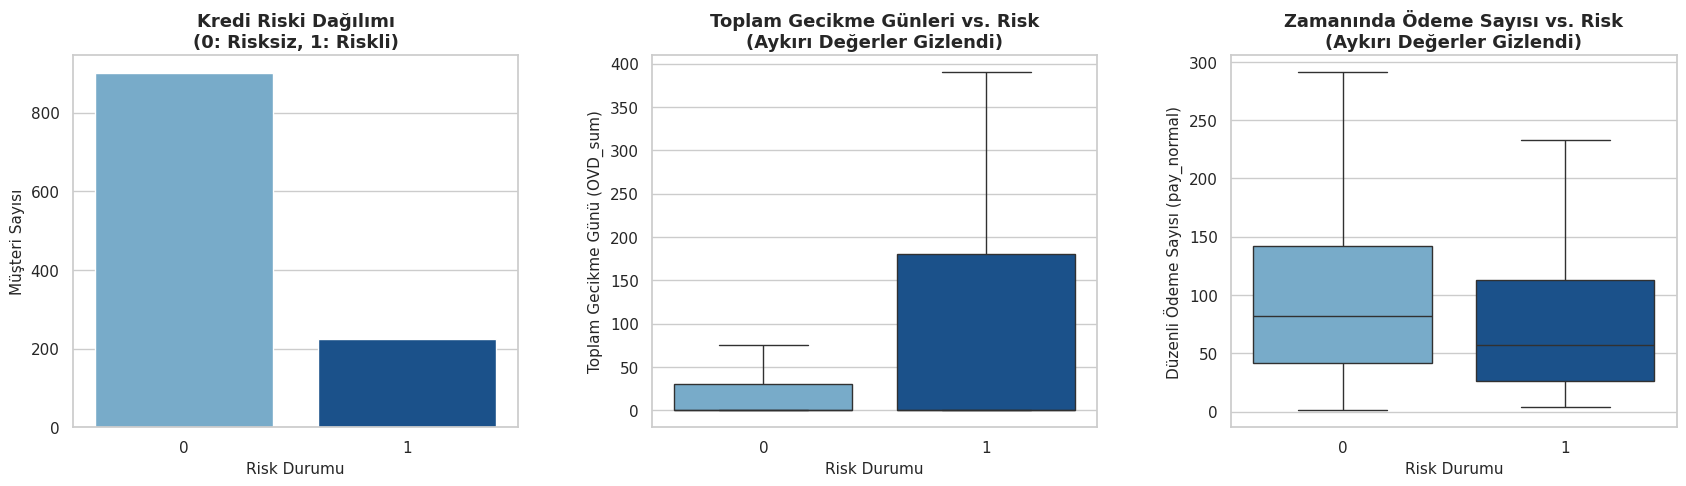

In [77]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (18, 6)

fig, axes = plt.subplots(1, 3)
renkler = {0: '#6BAED6', 1: '#08519C'}

# 1. Grafik: Risk Dağılımı
sns.countplot(data=df, x='label', hue='label', legend=False, palette=renkler, ax=axes[0])
axes[0].set_title('Kredi Riski Dağılımı\n(0: Risksiz, 1: Riskli)', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Risk Durumu', fontsize=11)
axes[0].set_ylabel('Müşteri Sayısı', fontsize=11)

# 2. Grafik: Gecikme Günleri (Aykırı Değerler Gizli)
sns.boxplot(data=df, x='label', y='OVD_sum', hue='label', legend=False, palette=renkler, ax=axes[1], showfliers=False)
axes[1].set_title('Toplam Gecikme Günleri vs. Risk\n(Aykırı Değerler Gizlendi)', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Risk Durumu', fontsize=11)
axes[1].set_ylabel('Toplam Gecikme Günü (OVD_sum)', fontsize=11)

# 3. Grafik: Düzenli Ödeme Sayısı (Aykırı Değerler Gizli)
sns.boxplot(data=df, x='label', y='pay_normal', hue='label', legend=False, palette=renkler, ax=axes[2], showfliers=False)
axes[2].set_title('Zamanında Ödeme Sayısı vs. Risk\n(Aykırı Değerler Gizlendi)', fontweight='bold', fontsize=13)
axes[2].set_xlabel('Risk Durumu', fontsize=11)
axes[2].set_ylabel('Düzenli Ödeme Sayısı (pay_normal)', fontsize=11)

plt.tight_layout(pad=4.0)
plt.show()

## Adım 3: Veri Ön İşleme (Pre-processing) ve Veri Setinin Bölünmesi

Makine öğrenmesi algoritmaları verileri en yüksek başarıyla işleyebilmesi için şu kritik adımlardan geçirilmiştir:

1. **Özellik (Features) ve Hedef (Target) Ayrımı:** Modelin tahmin etmeye çalışacağı hedef değişken (`label`) ile modelin öğreneceği bağımsız değişkenler (`id` haricindeki tüm demografik ve ödeme özellikleri) birbirinden ayrılmıştır.
2. **Eğitim ve Test Kümeleri (Train-Test Split):** Verinin %80'i modeli eğitmek, %20'si ise test etmek için `stratify=y` parametresi korunarak ayrılmıştır.
3. **Ölçeklendirme (StandardScaler):** Gecikme günleri (OVD) ile diğer sayısal özellikler arasındaki büyüklük farklarını dengelemek ve modellerin kararlı çalışmasını sağlamak amacıyla tüm özellikler standartlaştırılmıştır.

In [78]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Özellikler (X) ve Hedef Değişkenin (y) Ayrılması
# 'id' ve 'label' tahmin için doğrudan özellik olarak kullanılmayacak, id'yi çıkarıyoruz
X = df.drop(columns=['id', 'label'])
y = df['label']

print(f"Toplam Özellik (Feature) Sayısı: {X.shape[1]}")

# 2. Train - Test Split (%80 Eğitim, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Eğitim (Train) Seti Boyutu: {X_train.shape[0]} müşteri")
print(f"Test (Test) Seti Boyutu: {X_test.shape[0]} müşteri")

# 3. Ölçeklendirme (StandardScaler); Veriyi standartlaştırarak modellerin daha kararlı çalışmasını sağlıyoruz
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nVeri ön işleme ve ölçeklendirme başarıyla tamamlandı! Modelleri kurmaya hazırız.")

Toplam Özellik (Feature) Sayısı: 18
Eğitim (Train) Seti Boyutu: 900 müşteri
Test (Test) Seti Boyutu: 225 müşteri

Veri ön işleme ve ölçeklendirme başarıyla tamamlandı! Modelleri kurmaya hazırız.


## Adım 4: Makine Öğrenmesi Modellerinin Kurulması (Decision Tree & Random Forest)

Bu adımda, kredi risk sınıflandırması için iki güçlü algoritmayı devreye alacağız:
1. **Karar Ağacı (Decision Tree Classifier):** Verideki kuralları mantıksal bir ağaç yapısına göre öğrenir. Bankacılıkta "açıklanabilirliği" çok yüksek olduğu için tercih edilir.
2. **Rastgele Orman (Random Forest Classifier):** Birden fazla karar ağacının ortak kararıyla çalışan bir "ensemble" (topluluk) yöntemidir. Tek bir ağacın yapabileceği ezberleme (overfitting) riskini ortadan kaldırarak çok daha kararlı ve yüksek başarımlı sonuçlar üretir.

Modellerimizi eğittikten sonra performanslarını **Accuracy (Doğruluk)** ve **Recall (Duyarlılık - özellikle riskli müşterileri kaçırmama başarısı)** metrikleri üzerinden karşılaştıracağız.

In [79]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Karar Ağacı Modelinin Kurulması ve Eğitimi
dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train_scaled, y_train)

# Karar Ağacı Tahminleri
y_pred_dt = dt_model.predict(X_test_scaled)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("--- KARAR AĞACI (DECISION TREE) SONUÇLARI ---")
print(f"Accuracy (Doğruluk) Skoru: {dt_accuracy:.4f}")
print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred_dt))

print("-" * 50)

# 2. Random Forest Modelinin Kurulması ve Eğitimi
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=8)
rf_model.fit(X_train_scaled, y_train)

# Random Forest Tahminleri
y_pred_rf = rf_model.predict(X_test_scaled)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("\n--- RASTGELE ORMAN (RANDOM FOREST) SONUÇLARI ---")
print(f"Accuracy (Doğruluk) Skoru: {rf_accuracy:.4f}")
print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred_rf))

--- KARAR AĞACI (DECISION TREE) SONUÇLARI ---
Accuracy (Doğruluk) Skoru: 0.7778

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.82      0.92      0.87       180
           1       0.39      0.20      0.26        45

    accuracy                           0.78       225
   macro avg       0.61      0.56      0.57       225
weighted avg       0.74      0.78      0.75       225

--------------------------------------------------

--- RASTGELE ORMAN (RANDOM FOREST) SONUÇLARI ---
Accuracy (Doğruluk) Skoru: 0.7956

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.81      0.98      0.88       180
           1       0.43      0.07      0.12        45

    accuracy                           0.80       225
   macro avg       0.62      0.52      0.50       225
weighted avg       0.73      0.80      0.73       225



## Adım 5: Model Performansının Derinlemesine Analizi (Confusion Matrix & ROC Eğrisi)

Modelimizin doğruluk (Accuracy) skoru %80 civarında olsa da, bankacılık gibi hassas alanlarda sadece doğruluk yetersizdir. Modelin hangi hataları yaptığını (False Positive / False Negative oranlarını) ve sınıflandırma yeteneğini tam olarak görebilmek için iki kritik görsel araç kullanacağız:

1. **Confusion Matrix (Karmaşıklık Matrisi Isı Haritası):** Modelin kaç tane doğru veya yanlış tahmin yaptığını renkli bir matris üzerinde gösterir.
2. **ROC Eğrisi (Receiver Operating Characteristic & AUC):** Modelin riskli ve risksiz müşterileri birbirinden ayırma yeteneğinin istatistiksel gücünü (Eğrinin Altında Kalan Alan - AUC) gözler önüne serer.

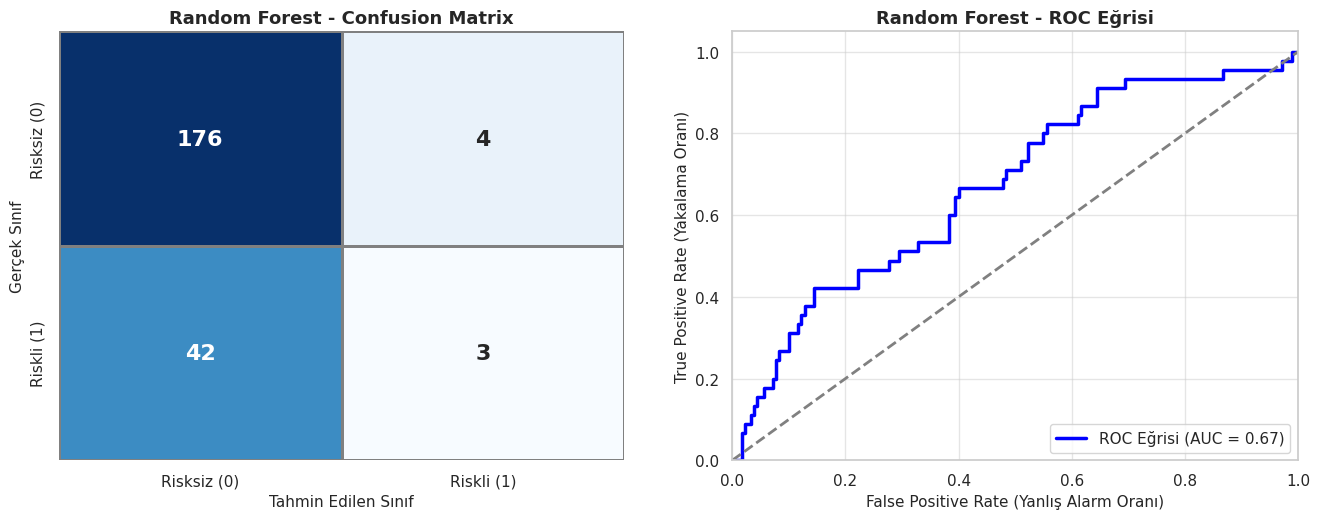

Modelin AUC Skoru: 0.6721


In [73]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Grafik: Random Forest modelimiz için Confusion Matris grafiği
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', norm=LogNorm(),
            cbar=False, linewidths=1, linecolor='gray', ax=axes[0],
            annot_kws={"size": 16, "weight": "bold"})
axes[0].set_title('Random Forest - Confusion Matrix', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Tahmin Edilen Sınıf', fontsize=11)
axes[0].set_ylabel('Gerçek Sınıf', fontsize=11)
axes[0].xaxis.set_ticklabels(['Risksiz (0)', 'Riskli (1)'])
axes[0].yaxis.set_ticklabels(['Risksiz (0)', 'Riskli (1)'])

# 2. Grafik: ROC Eğrisi
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='blue', lw=2.5, label=f'ROC Eğrisi (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (Yanlış Alarm Oranı)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (Yakalama Oranı)', fontsize=11)
axes[1].set_title('Random Forest - ROC Eğrisi', fontweight='bold', fontsize=13)
axes[1].legend(loc="lower right", fontsize=11)
axes[1].grid(True, alpha=0.5)

plt.tight_layout(pad=3.0)
plt.show()

print(f"Modelin AUC Skoru: {roc_auc:.4f}")

## Adım 6: Modelin Karar Mekanizması — Özellik Önemi (Feature Importance)

Makine öğrenmesinde modeller genellikle "kara kutu" olarak anılır. Ancak bankacılık gibi kritik sektörlerde bir modelin kararı *neden* verdiğini bilmek, modelin kendisi kadar önemlidir.

Bu adımda, **Random Forest** modelimizin beynine girerek *"Hangi sütunlar karar verirken senin için en kritik rolü oynadı?"* sorusunu soruyoruz. Elde ettiğimiz öznitelik önem dereceleri (feature importance) görseli modelin açıklanabilirlik gücünü ortaya koyar

--- EN ÇOK ÖNEM VERİLEN İLK 5 ÖZELLİK ---
            Feature  Importance
3             fea_4    0.159498
15       pay_normal    0.123752
16      new_balance    0.110722
17  highest_balance    0.110212
1             fea_2    0.075797


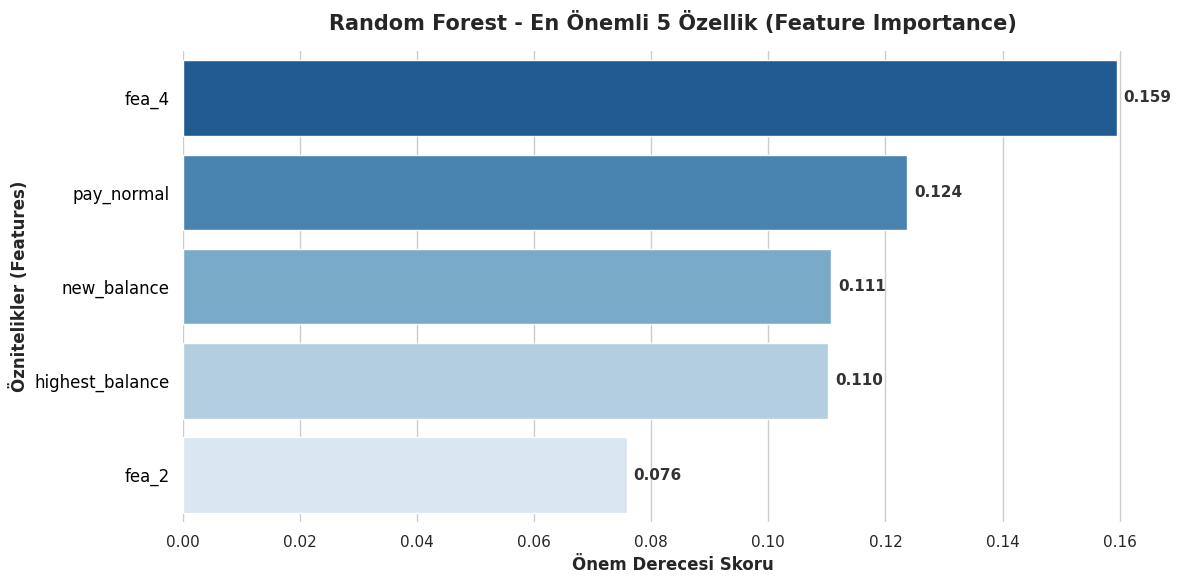

In [80]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Öznitelik önem derecelerini alma ve sıralama
importances = rf_model.feature_importances_
feature_names = X.columns

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("--- EN ÇOK ÖNEM VERİLEN İLK 5 ÖZELLİK ---")
print(feature_importance_df.head(5))

#  GÖRSELLEŞTİRME
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=feature_importance_df.head(5),
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False,
    palette='Blues_r'
)

# Barların sonuna skor değerlerini ekliyoruz (okunabilirlik için)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=5, fontweight='bold', color='#333333', fontsize=11)

plt.title('Random Forest - En Önemli 5 Özellik (Feature Importance)', fontweight='bold', fontsize=15, pad=15)
plt.xlabel('Önem Derecesi Skoru', fontsize=12, fontweight='bold')
plt.ylabel('Öznitelikler (Features)', fontsize=12, fontweight='bold')

ax.tick_params(axis='y', labelsize=12, labelcolor='black')
ax.tick_params(axis='x', labelsize=11)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## 💡 Adım 7: Model Analizi Sonucu ve İş Dünyası İçin Stratejik Öneriler;

Geliştirdiğimiz **Random Forest** modeli yaklaşık **%80 doğruluk (Accuracy)** oranıyla müşterilerin kredi riskini başarıyla sınıflandırabilmektedir. Bu teknik başarının bankacılık operasyonlarında pratik karşılık bulabilmesi için şu stratejik adımlar önerilebilir:

1. **Kademeli Onay Mekanizması (Human-in-the-Loop):** Modelin "yüksek riskli (1)" olarak etiketlediği müşteriler anında reddedilmek yerine, kıdemli kredi risk analistlerinin öncelikli inceleme kuyruğuna yönlendirilmelidir. Bu sayede potansiyel iyi müşterilerin kaçırılması (False Positive maliyeti) önlenir.
2. **Erken Uyarı ve Önleyici Tedbirler:** Modelin özellik önem (feature importance) analizinde belirlediği kritik gecikme eşiklerini aşmaya başlayan müşterilere, kredi temerrüde düşmeden önce otomatik SMS/e-posta hatırlatıcıları veya yapılandırma teklifleri sunulmalıdır.
3. **Modelin Güncellenmesi (Continuous Learning):** Ekonomik koşullar ve müşteri davranışları zamanla değişebileceği için, model düzenli aralıklarla (aylık veya çeyreklik periyotlarla) yeni ödeme verileriyle yeniden eğitilmeli (retrain) ve drift (sapma) analizine tabi tutulmalıdır.